# GEOL 415 Lab 09 -- Explainable AI

We've learned a lot about how to train data-driven models to predict a targeted outcome given appropriate inputs. We spent a lot of time visualizing results, comparing models with different hyperparameters, and visualizing feature importances. Today, we'll spend some more time thinking about **how** these models make decisions using explainable A.I. tools.

## Learning Objectives
By the end of this lab, you should be able to:

- **Distinguish** a model's *performance* (how accurate are its predictions?) from its *reasoning* (which inputs drive those predictions?), and explain why explainability matters for scientific applications.
- **Describe** permutation feature importance (PFI): what it measures, how it is computed, and why it is evaluated on held-out data.
- **Implement** PFI from scratch with `pandas` and `NumPy` by shuffling one test-set column at a time while holding all other columns fixed.
- **Apply** `sklearn.inspection.permutation_importance` and verify that it reproduces your hand-built results.
- **Interpret** importances: their units (increase in RMSE, in pH units), their spread across repeats, and what near-zero values do and do not tell you.
- **Compare** PFI against XGBoost's built-in *gain* importance and explain why two importance metrics can disagree.
- **Recognize** the limits of feature importance: correlated features, data leakage, and the difference between what a *model* relies on and what is true in nature.

# 0 - Startup

Import the following modules and make sure you're in the correct virtual programming environment below.

**Note:** cells containing `____` are blanks for you to fill in. They will not run until you replace every `____` with the correct code.

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

# 1 - Load data

Today we will be training another XGBoost model, this time to predict **pH** at measurement sites throughout the glacial aquifer system (GLAC) of the contiguous United States. Data are retrieved from [Brown, C.J. et al., 2019](https://www.sciencebase.gov/catalog/item/5efe239782ce3fd7e8a82651). These data were used in the following study:

+ Stackelberg, P.E., Belitz, K., Brown, C.J., Erickson, M.L., Elliott, S.M., Kauffman, L.J., Ransom, K.M. and Reddy, J.E. (2021), Machine Learning Predictions of pH in the Glacial Aquifer System, Northern USA. Groundwater, 59: 352-368. https://doi.org/10.1111/gwat.13063


We will be performing an abridged analysis inspired by the results of the above paper. Let's load a subet of their (massive) dataset below.

In [62]:
df = pd.read_csv('GLAC_pH.csv')
df.head()

,Number,Temperature,pH,Ca,Mg,K,Na,Alkalinity,Cl,Si,...,As_remark,As,O(0),C(4),Well_depth,Bedrock_lithology,State,Terrane,si_Calcite,si_Kaolinite
0,16,17.00,7.16,82.19,19.43,1.43,27.61,282.0,13.971,16.74,...,NaN,0.003568,0.46,0.003,25.00,carbonate rock,IL,1B,0.0004,4.4588
1,27,14.75,6.92,170.00,37.00,1.30,5.70,451.0,9.100,12.00,...,NaN,NaN,0.09,NaN,6.71,non-carbonate sedimentary rock,IN,1B,0.1847,NaN
2,28,13.95,6.99,130.00,35.00,1.40,7.60,426.0,8.000,13.00,...,NaN,NaN,0.08,NaN,12.20,non-carbonate sedimentary rock,IN,1B,0.1239,NaN
3,31,23.60,6.70,86.00,35.00,0.90,16.00,307.0,5.400,14.00,...,NaN,NaN,3.30,NaN,15.85,non-carbonate sedimentary rock,IN,1B,-0.3087,NaN
4,35,17.10,7.11,98.00,44.00,1.90,37.00,405.0,6.100,14.00,...,NaN,NaN,6.70,NaN,20.43,non-carbonate sedimentary rock,IN,1B,0.1494,NaN


### Check for NaN ("Not a Number", i.e. missing) values within each feature of the dataset

Online data can be messy, and one way this presents itself is in the form of **missing data**. Use the `.isna()` method associated with `pd.DataFrame` to find these culprits.

In [63]:
missing_vals = df.isna()
per_col_nan = missing_vals.isna()

# gives missing values as percentage of total number of rows
np.round(per_col_nan/df.shape[0], 3) * 100

per_col_nan

,Number,Temperature,pH,Ca,Mg,K,Na,Alkalinity,Cl,Si,...,As_remark,As,O(0),C(4),Well_depth,Bedrock_lithology,State,Terrane,si_Calcite,si_Kaolinite
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9650,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9651,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9652,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9653,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### Drop the following columns entirely because of their massive NaN count.

NOTE: we're also dropping si_calcite as this is a linear combination of features including pH, our target. Our results would be suspiciously good if we included that, as we would be giving our model the answer in a way.

In [64]:
# the worst offenders. PLUS some categorical stuff we won't need
# this includes well number, state
to_drop = ['N(5)_remark', 'Al_remark', 'Al', 'Mn_remark', 'Fe_remark', 
           'As_remark', 'As', 'O(0)', 'C(4)', 'si_Kaolinite', 'Number',
           'State', 'si_Calcite']

# inplace lets you not have to write "df = df.drop(columns=to_drop)"
# but this can cause headaches if you rerun cells out of order a bunch.
# Beware! or change this to "df = df.drop(columns=to_drop)"
df.drop(columns=to_drop, inplace=True)

Let's look at our pared down df

In [65]:
df

,Temperature,pH,Ca,Mg,K,Na,Alkalinity,Cl,Si,S(6),N(5),Mn,Fe,Well_depth,Bedrock_lithology,Terrane
0,17.00,7.16,82.19,19.43,1.43,27.61,282.0,13.971,16.74,48.186,0.5,0.09939,2.1590,25.00,carbonate rock,1B
1,14.75,6.92,170.00,37.00,1.30,5.70,451.0,9.100,12.00,48.000,21.0,0.02000,0.0499,6.71,non-carbonate sedimentary rock,1B
2,13.95,6.99,130.00,35.00,1.40,7.60,426.0,8.000,13.00,44.000,0.5,0.65000,1.5000,12.20,non-carbonate sedimentary rock,1B
3,23.60,6.70,86.00,35.00,0.90,16.00,307.0,5.400,14.00,13.000,0.5,0.62000,0.0499,15.85,non-carbonate sedimentary rock,1B
4,17.10,7.11,98.00,44.00,1.90,37.00,405.0,6.100,14.00,40.000,0.5,0.37000,0.0499,20.43,non-carbonate sedimentary rock,1B
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9650,12.00,7.10,13.30,5.50,NaN,4.26,48.0,4.000,21.00,1.770,0.5,0.02000,0.0499,53.35,Unconsolidated,1G
9651,12.00,8.15,27.00,3.60,NaN,4.70,74.0,6.000,5.40,6.000,0.5,0.02000,0.0499,65.85,Unconsolidated,1G
9652,12.00,9.80,16.30,12.00,NaN,9.30,69.0,7.000,29.40,14.000,4.5,0.02000,0.0200,34.15,Unconsolidated,1G
9653,12.00,8.11,59.40,16.00,NaN,25.20,233.0,3.000,42.50,54.000,0.5,0.09790,0.0780,31.40,Unconsolidated,1G


Notice we didn't get rid of every NaN data point. We can do this by dropping rows that contain a NaN at all. There are other ways to handle NaN values, but for today let's just be rid of them.

### Q: use `.dropna()` to drop all rows containing NaN values

In [66]:
df.dropna(axis=0, inplace=True) # 0 is default. 0 == drops rows. 1 == drops columns
df

,Temperature,pH,Ca,Mg,K,Na,Alkalinity,Cl,Si,S(6),N(5),Mn,Fe,Well_depth,Bedrock_lithology,Terrane
0,17.00,7.16,82.190000,19.430000,1.43,27.610000,282.0,13.971000,16.740000,48.186,0.5,0.09939,2.1590,25.00,carbonate rock,1B
1,14.75,6.92,170.000000,37.000000,1.30,5.700000,451.0,9.100000,12.000000,48.000,21.0,0.02000,0.0499,6.71,non-carbonate sedimentary rock,1B
2,13.95,6.99,130.000000,35.000000,1.40,7.600000,426.0,8.000000,13.000000,44.000,0.5,0.65000,1.5000,12.20,non-carbonate sedimentary rock,1B
3,23.60,6.70,86.000000,35.000000,0.90,16.000000,307.0,5.400000,14.000000,13.000,0.5,0.62000,0.0499,15.85,non-carbonate sedimentary rock,1B
4,17.10,7.11,98.000000,44.000000,1.90,37.000000,405.0,6.100000,14.000000,40.000,0.5,0.37000,0.0499,20.43,non-carbonate sedimentary rock,1B
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9481,12.00,8.11,100.000000,25.500000,9.59,65.800003,328.9,19.700001,27.700001,139.000,0.5,0.48700,0.2060,73.17,non-carbonate sedimentary rock,2E
9482,12.00,8.43,117.000000,44.000000,22.40,26.600000,441.3,3.060000,39.799999,158.000,0.5,0.51300,0.2360,54.88,non-carbonate sedimentary rock,2E
9483,12.00,7.67,299.000000,104.000000,8.69,28.400000,333.0,37.099998,32.000000,824.000,0.5,1.55000,1.6000,12.20,non-carbonate sedimentary rock,2E
9484,12.00,7.83,219.000000,58.400002,11.20,145.000000,324.8,62.099998,29.299999,653.000,0.5,1.29000,0.3570,18.29,non-carbonate sedimentary rock,2E


This leaves us with thousands of data points with which we can train an XGBoost model.

# 1.5 - Prepare data for model training

You know the drill -- we will first isolate our target variable (pH) from the data to create our two arrays `X` and `y`. Then, we will train/test split this dataset!

In [67]:
# this is one of many ways I could think of doing this. Separate target from predictors
X, y = df.drop(columns=['pH']), df['pH']
# housekeeping for XGBoost compatibility
X['Bedrock_lithology'] = X['Bedrock_lithology'].astype('category')
X["Terrane"] = X["Terrane"].astype("category")

# split your data
test_prop = 0.2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_prop, random_state=42, shuffle=True)

# check dataset sizes -- train should be much larger
print('train samples', X_train.shape[0], ', test samples', X_test.shape[0])

train samples 6684 , test samples 1671


# 2 -- Initialize and train an XGBoost model
This should be identical to last week's lab, though you may want to mess around with hyperparameters to get a good fit.

**NOTE:** we are evaluating performance on the test set as we go along. This is technically a no-no, as we should be using validation here. But, since we are not focusing on hyperparameter optimization, this is technically OK.

In [68]:
model = xgb.XGBRegressor(
    n_estimators=250,
    learning_rate=0.06,
    max_depth=4,
    subsample=0.8,
    random_state=42,
    eval_metric='rmse',
)

model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=True,
)

y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)
print('Model trained!')

[0]	validation_0-rmse:0.66023	validation_1-rmse:0.64994
[1]	validation_0-rmse:0.63756	validation_1-rmse:0.62830
[2]	validation_0-rmse:0.61616	validation_1-rmse:0.60842
[3]	validation_0-rmse:0.59683	validation_1-rmse:0.59020
[4]	validation_0-rmse:0.57866	validation_1-rmse:0.57303
[5]	validation_0-rmse:0.56250	validation_1-rmse:0.55835
[6]	validation_0-rmse:0.54727	validation_1-rmse:0.54426
[7]	validation_0-rmse:0.53340	validation_1-rmse:0.53179
[8]	validation_0-rmse:0.52031	validation_1-rmse:0.52021
[9]	validation_0-rmse:0.50848	validation_1-rmse:0.50924
[10]	validation_0-rmse:0.49700	validation_1-rmse:0.49924
[11]	validation_0-rmse:0.48686	validation_1-rmse:0.49038
[12]	validation_0-rmse:0.47764	validation_1-rmse:0.48238
[13]	validation_0-rmse:0.46832	validation_1-rmse:0.47433
[14]	validation_0-rmse:0.46032	validation_1-rmse:0.46732
[15]	validation_0-rmse:0.45315	validation_1-rmse:0.46150
[16]	validation_0-rmse:0.44654	validation_1-rmse:0.45604
[17]	validation_0-rmse:0.44006	validation

In [69]:
# get r2 score for later plot
r2 = r2_score(y_test, y_pred_test)

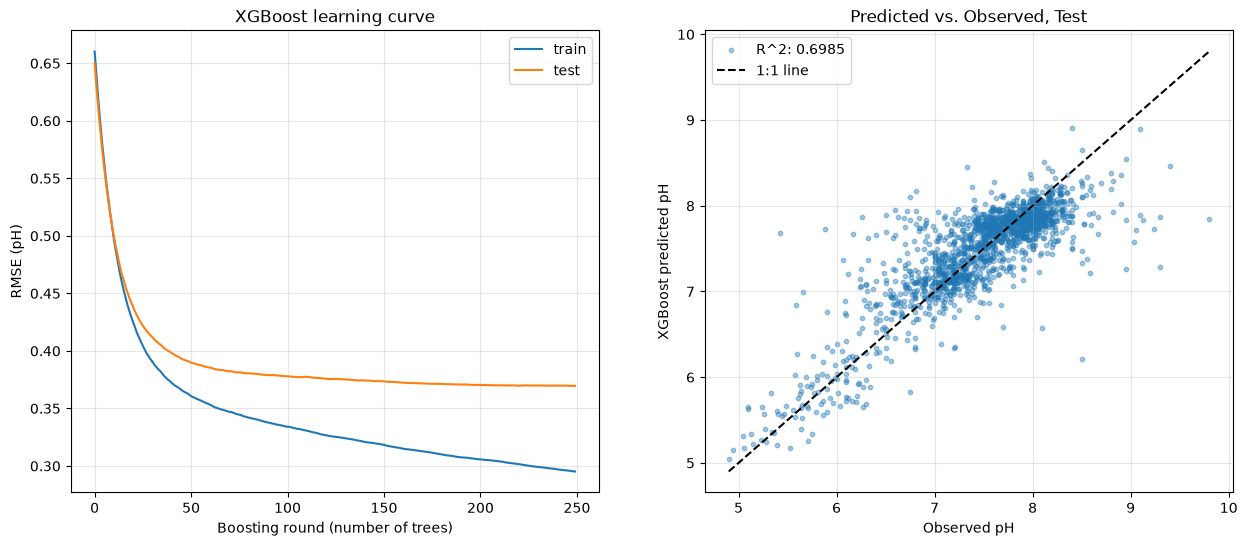

In [70]:
results = model.evals_result()
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# plot train/test RMSE 
ax1.plot(results['validation_0']['rmse'], label='train')
ax1.plot(results['validation_1']['rmse'], label='test')
ax1.set_xlabel('Boosting round (number of trees)')
ax1.set_ylabel('RMSE (pH)')
ax1.set_title('XGBoost learning curve')
ax1.legend()
ax1.grid(alpha=0.3)

# plot prediction 1:1 line
ax2.scatter(y_test, y_pred_test, s=10, alpha=0.4, label=f'R^2: {r2:.04f}')
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
ax2.plot(lims, lims, 'k--', label='1:1 line')
ax2.set_xlabel('Observed pH')
ax2.set_ylabel('XGBoost predicted pH')
ax2.set_title(f'Predicted vs. Observed, Test')
ax2.legend()
ax2.grid(alpha=0.3)

plt.show()

This looks reasonable! We could try to eke out better RMSE here, but I think we are good to go: the test RMSE has plateaued at roughly 0.37 pH units (the pH standard deviation across the dataset is ~0.7), so the model captures a good chunk of the variance in pH ($R^2 \approx 0.7$). Notice that the train curve keeps dropping while the test curve flattens: the model fits the data it was trained on better than data it hasn't seen. We'll keep that in mind.

### Conceptual Question 1

Our model achieves a test $R^2$ of about 0.7 and a test RMSE of about 0.37 pH units. Whether a model scores 0.7 or 0.99, does a good test score tell us the model is making its predictions for the *right* (e.g. chemically sensible) reasons? Explain, and give one example of how a model could achieve low error for the "wrong" reasons.

*Answer*: No because it only measures the statistical correlation and is seperate from scientific principles and does not gurantee our model is good in a chemically sensible way. One example would be  if samples that are acidic were measured at a lower temperature and basic samples were measured at a higher temperature and the model will not have that understanding of the chemical relationship between pH and temperature.

### Now, let's get a sense of why we get these predictions, and what inputs are most important here. **Enter: explainability**

# 3 -- Explainability

There is a small treasure trove of explainability libraries to figure out what features are most important in a model's predictions. Today, we'll focus on a method called Permutation Feature Importance, or PFI.

## Permutation feature importance

**The question PFI answers:** *"How much worse does my model get if the information in one feature is muddled?"*

**The idea.** If a trained model leans heavily on a feature, scrambling that feature should hurt its predictions. If the model ignores the feature, scrambling it should change nothing. PFI turns this into a number. For each feature $j$, we randomly **shuffle that column of the held-out data** (breaking its link to the target, while keeping its values and distribution intact), re-predict with the *already-trained* model, and measure how much the error increases relative to the unshuffled baseline. Because a single shuffle is just one random draw, we repeat it $K$ times and average:

$$\text{importance}_j \;=\; \underbrace{\frac{1}{K}\sum_{k=1}^{K}\text{RMSE}\!\left(y,\ \hat{f}\big(X^{(j,k)}_{\text{shuffled}}\big)\right)}_{\text{average error with feature } j \text{ shuffled}} \;-\; \underbrace{\text{RMSE}\!\left(y,\ \hat{f}(X)\right)}_{\text{baseline error}}$$

**How to read it.** Here the importance has the same units as our target: an importance of 0.3 means "shuffling this feature makes our pH predictions worse by 0.3 pH units of RMSE." A **large** value means the model relies on the feature; a value **near zero** means the model's predictions barely depend on it; small negative values are just noise (shuffling got lucky).

**Why people like it.** It is *model-agnostic* (it only needs a `predict` function), it needs *no retraining*, and it is measured on *held-out data*, so it reflects what the model relies on when making real predictions.

**Caveats we'll revisit at the end of the lab.** PFI tells you what the *model* relies on, not what is causally true in nature. Correlated features can share or mask each other's importance. And PFI is only as meaningful as the inputs you give the model.

## Part 1: DIY permutation importance 

You will perform PFI using runtime-optimal code from the sklearn library in a minute. Here, though, I want to show you how you can perform PFI yourself using Python. In words, PFI works as follows:

1) **Record** a baseline for your model's performance on the test data. You've already achieved this above.
2) **For** each input feature in the dataset:
    
    2a) **randomly** permute the TEST values of the input feature. Do this while holding all other features as they were.
    
    2b) `model.predict()` on the permuted test data (i.e. re-shuffled single column, fixed other columns). Record the error produced by this (i.e. RMSE)

    2c) **repeat** n times per feature to get a mean/standard deviation of model performance.

3) **Repeat** for all input features from X_test.

Below is the scaffold for a function that permutes a single feature of a dataset n times. Use this function in a loop setup below to iterate through your entire dataset.

In [75]:
def permute_feature_and_eval(model, X_data, y_true, colname, n = 30):
    X_pfp = X_data.copy()
    original = X_data[colname] 

    #initialize rmse
    rmse_results = []
    # loop over n shuffles

    for i in range(n):
        # shuffle column of dataframe
        # frac=1 shuffles ALL rows; .array drops the index so the assignment is purely positional
        X_pfp[colname] = original.sample(frac=1, random_state=i).array

        # evaluate model on Test targets using this new df. get RMSE.
        y_pred_pfp = model.predict(X_pfp)
        rmse = np.sqrt(mean_squared_error(y_true, y_pred_pfp))
        rmse_results.append(rmse)


    return rmse_results

### Conceptual Question 2

**(a)** PFI *shuffles* a feature's values rather than deleting the column or setting it to zero (or to its mean). Why? What does shuffling preserve, and what does it destroy?

**(b)** Why does `permute_feature_and_eval` repeat the shuffle `n = 30` times rather than shuffling once?

*Answer*: **a)** Shuffling preserves the structure of our dataset, however, the relationship between the target variable and the specific features are destroyed since shuffling will isolate the target from everything else. **b)** We use n=30  because doing it once will not gurantee that the dataset will be truly shuffled in the way that we think it will be (ie. shuffling once may lead to data points being close to their original value because the process is random and we do not know where each data point will go to). Therefore, by doing it 30 times, we gurantee that the shuffling really does shuffle our values to where the PFI will represent a more reliable value.

Now, iterate over the columns of your X_test dataset. For each feature, permute it n times and calculate the RMSE each time. Store your results in the `rmse_data` list, which we'll turn into a `pd.DataFrame`. NOTE that `importance` is calculated as the difference between the average permuted RMSE and our baseline (the unpermuted, optimized XGBoost model). That way, we have a relative sense of how much worse permutation does relative to our good model.

In [76]:
colnames = X_test.columns

rmse_data = []
baseline = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))

for col in colnames:
    rmse_arr = permute_feature_and_eval(model, X_test, y_test, col)

    rmse_data.append({'feature': col,
                    'avg_rmse': np.mean(rmse_arr),
                    'std_rmse':np.std(rmse_arr),
                    'importance': np.mean(rmse_arr) - baseline})
    print(col, f'mean rmse degradation: {np.mean(rmse_arr):.03f}')
rmse_df = pd.DataFrame(rmse_data).sort_values("importance", ascending=False)

Temperature mean rmse degradation: 0.397
Ca mean rmse degradation: 0.397
Mg mean rmse degradation: 0.375
K mean rmse degradation: 0.370
Na mean rmse degradation: 0.377
Alkalinity mean rmse degradation: 0.676
Cl mean rmse degradation: 0.375
Si mean rmse degradation: 0.375
S(6) mean rmse degradation: 0.374
N(5) mean rmse degradation: 0.380
Mn mean rmse degradation: 0.380
Fe mean rmse degradation: 0.384
Well_depth mean rmse degradation: 0.413
Bedrock_lithology mean rmse degradation: 0.374
Terrane mean rmse degradation: 0.445


In [77]:
rmse_df.head(5) # these are our top 5 most importance features!

,feature,avg_rmse,std_rmse,importance
5,Alkalinity,0.676318,0.009218,0.306740
14,Terrane,0.444742,0.004457,0.075165
12,Well_depth,0.413052,0.003636,0.043475
0,Temperature,0.397223,0.002205,0.027646
1,Ca,0.396847,0.002354,0.027269


## Plot the feature importances from above

Now that we have our importances, we can plot our results below. Remember, importance is a measure of "how much worse is our model when we shuffle feature X?" Fill in the blanks to arrive at a nice plot.

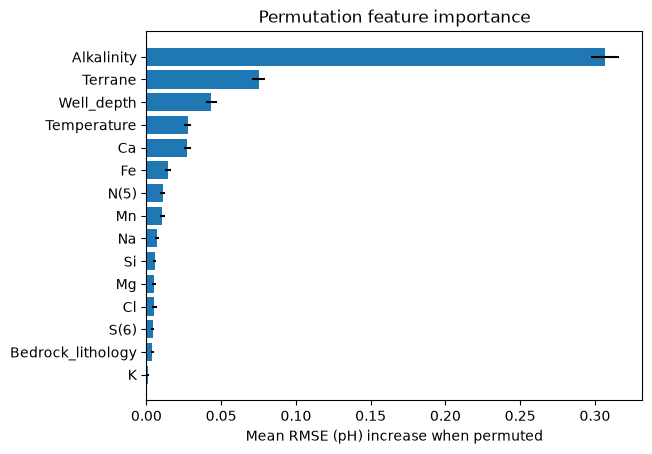

In [80]:
f, ax = plt.subplots()
ax.barh(range(rmse_df.shape[0]),
         rmse_df['importance'],
         xerr = rmse_df['std_rmse'],
         )
ax.invert_yaxis()
ax.plot() 
ax.set_yticks(range(rmse_df.shape[0]), rmse_df['feature'])
ax.set_title('Permutation feature importance')
ax.set_xlabel('Mean RMSE (pH) increase when permuted')
plt.show()

### Conceptual Question 3

Use your table and plot above (your exact numbers may differ slightly from the ones quoted in the key if you changed any hyperparameters).

**(a)** The baseline test RMSE is roughly 0.37. What does it mean, concretely and *with units*, that shuffling `Alkalinity` gives an importance of about 0.3?

**(b)** What would it mean if a feature had an importance of about 0?

*Answer*: **a)** Shuffling alkalinity giving an importance of 0.3 means that the concentration in GLAC is important for the model as it relies on it more heavily compared to other features for performance and prediction. **b)** An importance of 0 would mean that shuffling the values of that specific feature would have no impact on the model's performance.

## Part 2: The easy way out with sklearn

Phew! That was fun, if inefficient. Let's repeat the above analysis with the `permutation_importance` function from `sklearn.inspection`. The point of the earlier section is to show you what goes on under the hood of this function

In [81]:
from sklearn.inspection import permutation_importance

In [85]:
metric = 'neg_root_mean_squared_error' #sklearn-specific way of saying RMSE
r = permutation_importance(model, X_test, y_test,
                           n_repeats=30,
                           scoring=metric,
                           random_state=42)

features = X.columns
sorted_imp_idx = r.importances_mean.argsort()

for i in r.importances_mean.argsort()[::-1]:
    print(f"{features[i]:<18} "
            f"{r.importances_mean[i]:.3f}"
            f" +/- {r.importances_std[i]:.3f}")

Alkalinity         0.311 +/- 0.008
Terrane            0.076 +/- 0.004
Well_depth         0.045 +/- 0.005
Temperature        0.028 +/- 0.002
Ca                 0.027 +/- 0.002
Fe                 0.014 +/- 0.002
N(5)               0.012 +/- 0.002
Mn                 0.011 +/- 0.002
Na                 0.007 +/- 0.002
Si                 0.005 +/- 0.001
Mg                 0.005 +/- 0.001
Cl                 0.005 +/- 0.002
Bedrock_lithology  0.004 +/- 0.001
S(6)               0.004 +/- 0.001
K                  0.001 +/- 0.001


In [86]:
features

Index(['Temperature', 'Ca', 'Mg', 'K', 'Na', 'Alkalinity', 'Cl', 'Si', 'S(6)',
       'N(5)', 'Mn', 'Fe', 'Well_depth', 'Bedrock_lithology', 'Terrane'],
      dtype='str')

### Plot these results in a similar way below

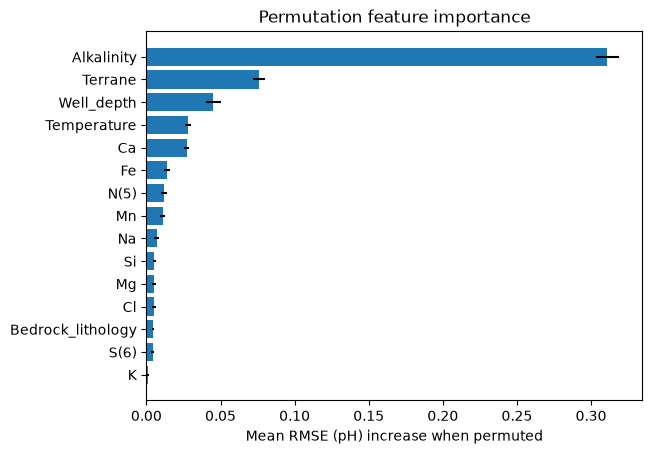

In [87]:
plt.barh(range(len(r.importances_mean)),
         r.importances_mean[sorted_imp_idx],
         xerr = r.importances_std[sorted_imp_idx])

plt.yticks(range(len(r.importances_mean)), features[sorted_imp_idx])
plt.title('Permutation feature importance')
plt.xlabel('Mean RMSE (pH) increase when permuted')
plt.show()

## Part 3: Compare against xgboost feature importance. Specifically, performance GAIN.

Plot side by side to better see the differences between the two explainability metrics.

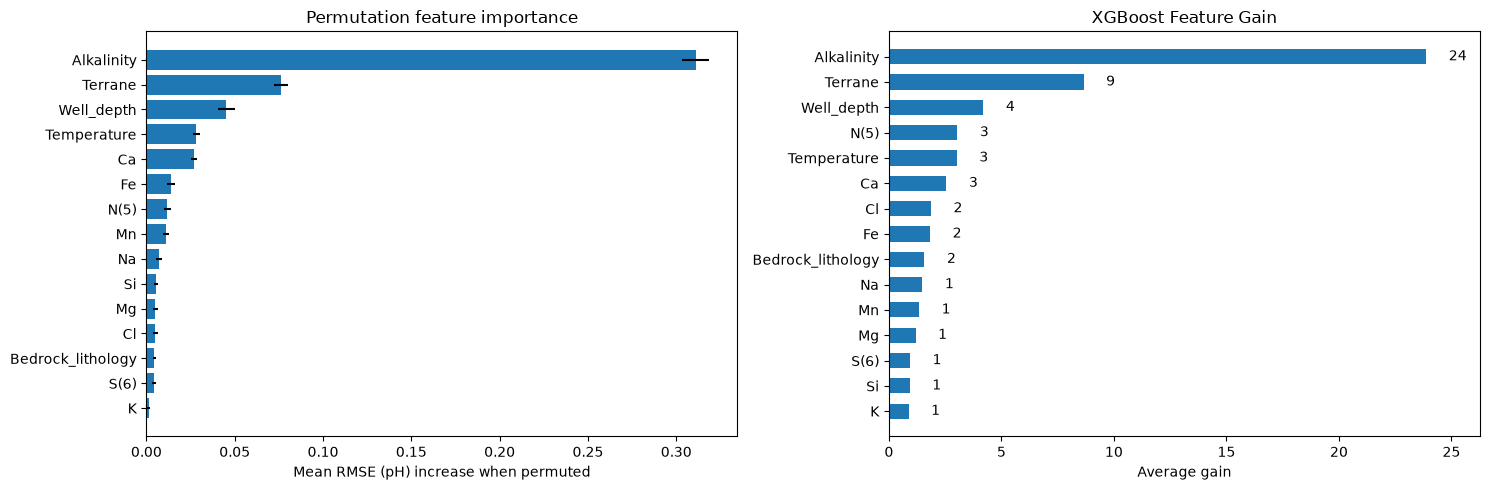

In [88]:
f, (ax1, ax2) = plt.subplots(1,2, figsize=(15,5))

# repro of earlier plot, this time in the subplot with XGB gain
ax1.barh(range(len(r.importances_mean)),
         r.importances_mean[sorted_imp_idx],
         xerr = r.importances_std[sorted_imp_idx])

ax1.set_yticks(range(len(r.importances_mean)), features[sorted_imp_idx])
ax1.set_title('Permutation feature importance')
ax1.set_xlabel('Mean RMSE (pH) increase when permuted')
# plt.show()

# now get XGB's gain metrics
xgb.plot_importance(model, ax=ax2, importance_type='gain', height=0.6,
                    title='XGBoost Feature Gain', xlabel='Average gain', ylabel=None, show_values=True, values_format='{v:.0f}')
plt.grid(False)
plt.tight_layout()

### Conceptual Question 4

**(a)** In a sentence or two each, what does XGBoost's *gain* measure, and what does PFI measure? What is the key difference in *when* and *on what data* each is computed?

**(b)** The two methods agree on the top three features (`Alkalinity`, `Terrane`, `Well_depth`) but disagree further down the ranking. For example, `Cl` is 7th by gain but near the bottom by PFI, and `N(5)` is 4th by gain but 7th by PFI. Propose a plausible explanation for why the rankings can differ. What does the *agreement* at the top tell you?

*Answer*: **a)** XGBoost's gain measures the contribution of a feature to the model's function. The PFI measures increases in error. **b)** Potential overfitting might have led to disagreement down the ranking. For Cl, it might be correlated with one or more of the higher ranking features and for N(5), there might be overfitting from XGBoost.

## Mini-Evals (please fill out!!!)

1. Please rate 1-5 how this lab was for you. 1 := this was too difficult, 5 := I could do this in my sleep.

*Answer*:4

2. What is something you wished I covered in this lab? 

*Answer*:NA

# Lab submission


Please `Restart` and `Run All` on this notebook and submit this lab when you are done!